# Part 1 — Understanding a Pretrained Vision Transformer

Loads torchvision's pretrained `vit_b_16` (ImageNet weights); nothing is trained here.

In [1]:
import json
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from PIL import Image
from torchvision.models import ViT_B_16_Weights, vit_b_16
from torchvision.transforms import functional as TF

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs" / "part1"
OUT.mkdir(parents=True, exist_ok=True)

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "pillow": Image.__version__,
    "device": str(device),
    "processor": platform.processor(),
    "os": platform.platform(),
    "checkpoint": "torchvision vit_b_16, ViT_B_16_Weights.IMAGENET1K_V1",
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
env

{'python': '3.13.2',
 'torch': '2.14.0+cpu',
 'torchvision': '0.29.0+cpu',
 'numpy': '2.2.2',
 'pillow': '12.3.0',
 'device': 'cpu',
 'processor': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'os': 'Windows-11-10.0.26300-SP0',
 'checkpoint': 'torchvision vit_b_16, ViT_B_16_Weights.IMAGENET1K_V1'}

In [2]:
weights = ViT_B_16_Weights.IMAGENET1K_V1
model = vit_b_16(weights=weights).to(device).eval()
preprocess = weights.transforms()
IMAGENET_CLASSES = weights.meta["categories"]

print("checkpoint url:", weights.url)
print("parameters:", sum(p.numel() for p in model.parameters()))
print("number of output classes:", len(IMAGENET_CLASSES))
print("\ncheckpoint preprocessing:\n", preprocess)

checkpoint url: https://download.pytorch.org/models/vit_b_16-c867db91.pth
parameters: 86567656
number of output classes: 1000

checkpoint preprocessing:
 ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## Task 1 — Image patches and model inputs

### 1.1 A patch function

`patchify` cuts an image into 16 × 16 patches, and `unpatchify` puts them back together to check nothing is lost.

In [3]:
def patchify(image, patch_size=16):
    """Split a (C, H, W) tensor into non-overlapping patches.

    Returns a tensor of shape (num_patches, C, patch_size, patch_size) in
    row-major order.
    """
    c, h, w = image.shape
    if h % patch_size or w % patch_size:
        raise ValueError(f"image size {(h, w)} is not divisible by patch size {patch_size}")
    grid_h, grid_w = h // patch_size, w // patch_size
    x = image.reshape(c, grid_h, patch_size, grid_w, patch_size)
    x = x.permute(1, 3, 0, 2, 4)  # (grid_h, grid_w, C, P, P)
    return x.reshape(grid_h * grid_w, c, patch_size, patch_size)


def unpatchify(patches, grid_h, grid_w):
    """Inverse of patchify: (N, C, P, P) -> (C, grid_h * P, grid_w * P)."""
    n, c, p, _ = patches.shape
    x = patches.reshape(grid_h, grid_w, c, p, p).permute(2, 0, 3, 1, 4)
    return x.reshape(c, grid_h * p, grid_w * p)


def load_display_image(path):
    """The same 224 x 224 region the model sees (resize 256 + centre crop), without normalization."""
    img = Image.open(path).convert("RGB")
    img = TF.resize(img, preprocess.resize_size, interpolation=preprocess.interpolation, antialias=True)
    img = TF.center_crop(img, preprocess.crop_size)
    return TF.to_tensor(img)  # (3, 224, 224), values in [0, 1]


demo_path = DATA / "part1_images" / "golden_retriever" / "golden_retriever_1.jpg"
demo = load_display_image(demo_path)
patches = patchify(demo, 16)

# sanity checks: round trip, and a patch equals the corresponding image slice
assert torch.equal(unpatchify(patches, 14, 14), demo)
assert torch.equal(patches[15], demo[:, 16:32, 16:32])  # index 15 = row 1, column 1
try:
    patchify(torch.zeros(3, 225, 224))
    raise AssertionError("expected a ValueError for a non-divisible size")
except ValueError:
    pass

print("image tensor:", tuple(demo.shape))
print("patches tensor:", tuple(patches.shape))

image tensor: (3, 224, 224)
patches tensor: (196, 3, 16, 16)


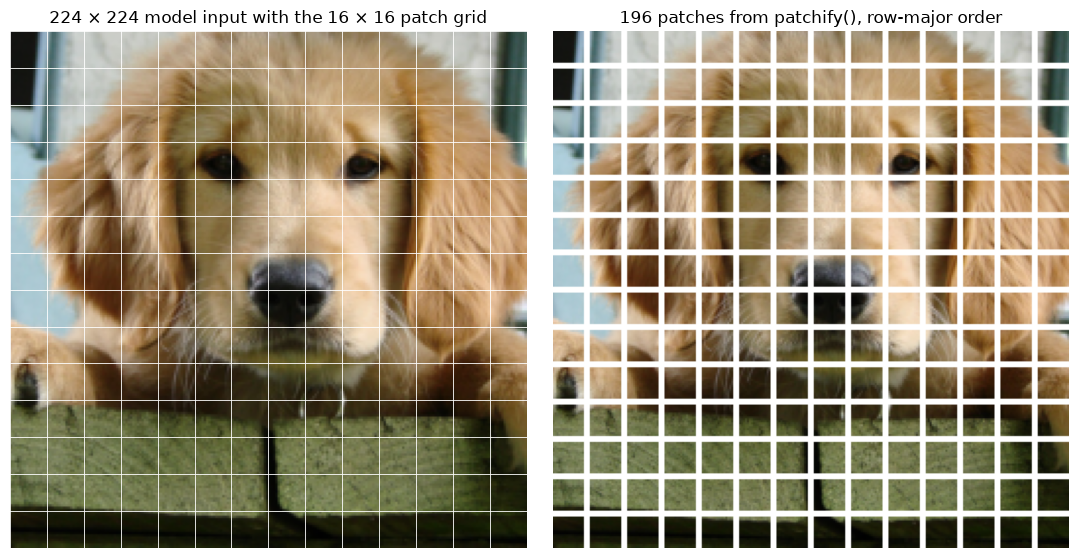

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(demo.permute(1, 2, 0))
for k in range(0, 225, 16):
    axes[0].axhline(k - 0.5, color="white", lw=0.6)
    axes[0].axvline(k - 0.5, color="white", lw=0.6)
axes[0].set_title("224 × 224 model input with the 16 × 16 patch grid")
axes[0].axis("off")

# draw the patches separated by a small gap so each one is visibly its own tile
gap, p, g = 3, 16, 14
canvas = torch.ones(3, g * p + (g - 1) * gap, g * p + (g - 1) * gap)
for idx, patch in enumerate(patches):
    r, c = divmod(idx, g)
    y, x = r * (p + gap), c * (p + gap)
    canvas[:, y:y + p, x:x + p] = patch
axes[1].imshow(canvas.permute(1, 2, 0))
axes[1].set_title(f"{len(patches)} patches from patchify(), row-major order")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(OUT / "task1_patches.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.2 Number of patches and sequence length

Checks against the real model that a 224 × 224 image gives 196 patches plus one CLS token, for 197 tokens.

In [5]:
x = preprocess(Image.open(demo_path).convert("RGB")).unsqueeze(0).to(device)

with torch.no_grad():
    patch_tokens = model._process_input(x)  # conv patch projection + flatten

# capture the sequence that actually enters the first transformer block
captured = {}
hook = model.encoder.layers[0].register_forward_hook(lambda m, inp, out: captured.update(seq=inp[0].shape))
with torch.no_grad():
    model(x)
hook.remove()

n_patches = (224 // 16) ** 2
print("patches by arithmetic:        ", n_patches)
print("patch tokens from the model:  ", tuple(patch_tokens.shape), "-> (batch, patches, hidden dim)")
print("class token parameter:        ", tuple(model.class_token.shape))
print("positional embedding:         ", tuple(model.encoder.pos_embedding.shape))
print("sequence into encoder block 0:", tuple(captured["seq"]), "-> (batch, 1 CLS + patches, hidden dim)")
assert patch_tokens.shape[1] == n_patches == len(patches)
assert captured["seq"][1] == n_patches + 1 == model.encoder.pos_embedding.shape[1]

patches by arithmetic:         196
patch tokens from the model:   (1, 196, 768) -> (batch, patches, hidden dim)
class token parameter:         (1, 1, 768)
positional embedding:          (1, 197, 768)
sequence into encoder block 0: (1, 197, 768) -> (batch, 1 CLS + patches, hidden dim)


### 1.3 What the patch projection, positional embeddings, and CLS token do

The patch projection turns each patch into a vector, the positional embeddings tell the model where each patch is, and the CLS token collects a summary of the whole image that is used for the prediction.

### 1.4 My patch picture versus the learned patch projection

My patches are just rearranged pixels, while the model multiplies each patch by learned weights; the check below shows that doing this by hand reproduces the model's patch tokens.

In [6]:
W = model.conv_proj.weight.detach()  # (768, 3, 16, 16)
b = model.conv_proj.bias.detach()
print("learned projection weight:", tuple(W.shape), "| bias:", tuple(b.shape))

my_patches = patchify(x[0], 16)                       # (196, 3, 16, 16) from the normalized input
flat = my_patches.reshape(my_patches.shape[0], -1)    # (196, 768) raw pixel values per patch
manual_tokens = flat @ W.reshape(W.shape[0], -1).T + b

max_diff = (manual_tokens - patch_tokens[0]).abs().max().item()
print(f"max |my patches x learned weights - model patch tokens| = {max_diff:.2e}")
assert torch.allclose(manual_tokens, patch_tokens[0], atol=1e-3)

learned projection weight: (768, 3, 16, 16) | bias: (768,)
max |my patches x learned weights - model patch tokens| = 2.26e-06


The model's learned patch weights, each shown as a small 16 × 16 colour filter.

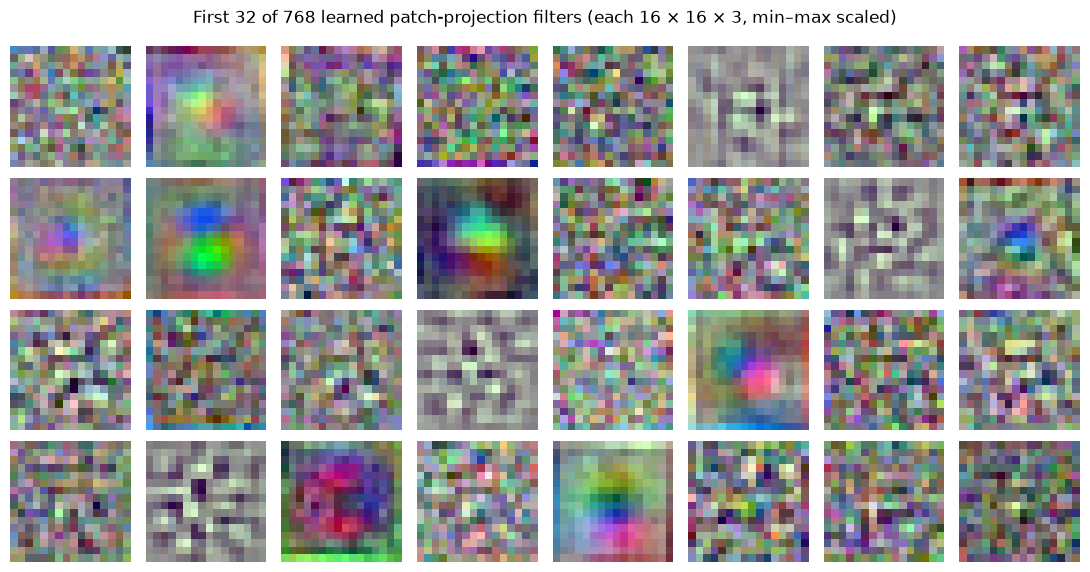

In [7]:
n_show = 32
fig, axes = plt.subplots(4, 8, figsize=(11, 5.8))
for ax, filt in zip(axes.flat, W[:n_show].cpu()):
    f = (filt - filt.min()) / (filt.max() - filt.min())  # rescale each filter to [0, 1] for display
    ax.imshow(f.permute(1, 2, 0), interpolation="nearest")
    ax.axis("off")
fig.suptitle(f"First {n_show} of 768 learned patch-projection filters (each 16 × 16 × 3, min–max scaled)")
plt.tight_layout()
plt.savefig(OUT / "task1_learned_filters.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.5 What the positional embeddings learned

How similar one marked position's embedding is to every other position on the 14 × 14 grid.

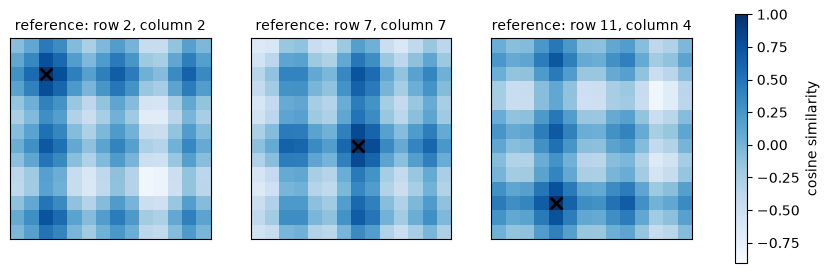

In [8]:
pos = model.encoder.pos_embedding[0, 1:].detach().cpu()  # drop the CLS position -> (196, 768)
pos = pos / pos.norm(dim=1, keepdim=True)
pos_sim = (pos @ pos.T).reshape(196, 14, 14)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (r, c) in zip(axes, [(2, 2), (7, 7), (11, 4)]):
    im = ax.imshow(pos_sim[r * 14 + c], cmap="Blues", vmin=float(pos_sim.min()), vmax=1.0)
    ax.plot(c, r, marker="x", color="black", markersize=9, mew=2)
    ax.set_title(f"reference: row {r}, column {c}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.85, label="cosine similarity")
plt.savefig(OUT / "task1_positional_similarity.png", dpi=150, bbox_inches="tight")
plt.show()

The cross shape shows the model learned the grid's rows and columns on its own.

## Task 2 — Predictions on a small image collection

### 2.1 Images and labels

20 images (5 categories × 4) from Wikimedia Commons, with sources in `data/image_sources.csv`, each matched to its ImageNet class by name.

In [9]:
CATEGORY_TO_IMAGENET = {
    "golden_retriever": "golden retriever",
    "zebra": "zebra",
    "school_bus": "school bus",
    "banana": "banana",
    "acoustic_guitar": "acoustic guitar",
}
CATEGORIES = list(CATEGORY_TO_IMAGENET)

label_map = []
for cat, name in CATEGORY_TO_IMAGENET.items():
    matches = [i for i, c in enumerate(IMAGENET_CLASSES) if c == name]
    assert len(matches) == 1, f"{name!r} should appear exactly once in the label list"
    label_map.append({"category": cat, "imagenet_index": matches[0], "imagenet_label": name})
label_map = pd.DataFrame(label_map)
label_map.to_csv(OUT / "label_mapping.csv", index=False)
CAT_TO_IDX = dict(zip(label_map.category, label_map.imagenet_index))
label_map

,category,imagenet_index,imagenet_label
0,golden_retriever,207,golden retriever
1,zebra,340,zebra
2,school_bus,779,school bus
3,banana,954,banana
4,acoustic_guitar,402,acoustic guitar


In [10]:
sources = pd.read_csv(DATA / "image_sources.csv")
assert sources.groupby("category").size().eq(4).all() and len(sources) == 20
assert all((ROOT / f).exists() for f in sources.file)
pd.set_option("display.max_colwidth", 60)
sources[["file", "category", "author", "license", "source_page"]]

,file,category,author,license,source_page
0,data/part1_images/golden_retriever/golden_retriever_1.jpg,golden_retriever,MichaelMcPhee,CC BY 3.0,https://commons.wikimedia.org/wiki/File:Callie_the_golde...
1,data/part1_images/golden_retriever/golden_retriever_2.jpg,golden_retriever,Pharaoh Hound,CC BY 2.5,https://commons.wikimedia.org/wiki/File:Golden_Retriever...
2,data/part1_images/golden_retriever/golden_retriever_3.jpg,golden_retriever,Helle316,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Golden_Retriever...
3,data/part1_images/golden_retriever/golden_retriever_4.jpg,golden_retriever,Dietmar Rabich,CC BY-SA 4.0,"https://commons.wikimedia.org/wiki/File:D%C3%BClmen,_Hau..."
4,data/part1_images/zebra/zebra_1.jpg,zebra,Yathin S Krishnappa,CC BY-SA 3.0,https://commons.wikimedia.org/wiki/File:Equus_quagga_bur...
5,data/part1_images/zebra/zebra_2.jpg,zebra,Charles J. Sharp,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Burchell%27s_zeb...
6,data/part1_images/zebra/zebra_3.jpg,zebra,Charles J. Sharp,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Burchell%27s_zeb...
7,data/part1_images/zebra/zebra_4.jpg,zebra,Diego Delso,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Cebras_de_Burche...
8,data/part1_images/school_bus/school_bus_1.jpg,school_bus,Ktkvtsh,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Ouachita_Parish_...
9,data/part1_images/school_bus/school_bus_2.jpg,school_bus,Crisco 1492,CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:School_bus_parke...


### 2.2 Running the model

Runs all 20 images through the model with its own preprocessing and saves the probabilities.

In [11]:
BATCH = 4
paths = [ROOT / f for f in sources.file]
probs = []
with torch.no_grad():
    for i in range(0, len(paths), BATCH):
        batch = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths[i:i + BATCH]]).to(device)
        probs.append(torch.softmax(model(batch), dim=1).cpu())
probs = torch.cat(probs)
np.save(OUT / "vit_probabilities.npy", probs.numpy())
print("probability matrix:", tuple(probs.shape), "| rows sum to", round(probs.sum(1).mean().item(), 4))

probability matrix: (20, 1000) | rows sum to 1.0


### 2.3 Top-five predictions for every image

In [12]:
top5_p, top5_i = probs.topk(5, dim=1)
rows = []
for n, row in sources.iterrows():
    true_idx = CAT_TO_IDX[row.category]
    for rank in range(5):
        rows.append({
            "image": Path(row.file).name,
            "true_label": IMAGENET_CLASSES[true_idx],
            "rank": rank + 1,
            "predicted_label": IMAGENET_CLASSES[top5_i[n, rank]],
            "probability": round(top5_p[n, rank].item(), 4),
            "is_true_label": bool(top5_i[n, rank] == true_idx),
        })
top5 = pd.DataFrame(rows)
top5.to_csv(OUT / "top5_predictions.csv", index=False)

with pd.option_context("display.max_rows", 200):
    display(top5)

,image,true_label,rank,predicted_label,probability,is_true_label
0,golden_retriever_1.jpg,golden retriever,1,golden retriever,0.8947,True
1,golden_retriever_1.jpg,golden retriever,2,cocker spaniel,0.0037,False
2,golden_retriever_1.jpg,golden retriever,3,tennis ball,0.0023,False
3,golden_retriever_1.jpg,golden retriever,4,doormat,0.0020,False
4,golden_retriever_1.jpg,golden retriever,5,Labrador retriever,0.0018,False
5,golden_retriever_2.jpg,golden retriever,1,golden retriever,0.8657,True
6,golden_retriever_2.jpg,golden retriever,2,Irish setter,0.0085,False
7,golden_retriever_2.jpg,golden retriever,3,Sussex spaniel,0.0047,False
8,golden_retriever_2.jpg,golden retriever,4,curly-coated retriever,0.0036,False
9,golden_retriever_2.jpg,golden retriever,5,cocker spaniel,0.0033,False


### 2.4 Top-one accuracy and confusion matrix

The extra "other ImageNet class" column catches wrong answers that fall outside my 5 categories.

In [13]:
true_idx = torch.tensor([CAT_TO_IDX[c] for c in sources.category])
pred_idx = top5_i[:, 0]

summary = pd.DataFrame({
    "image": [Path(f).name for f in sources.file],
    "category": sources.category,
    "top1_label": [IMAGENET_CLASSES[i] for i in pred_idx],
    "top1_prob": top5_p[:, 0].numpy().round(4),
    "true_label_prob": probs[torch.arange(len(probs)), true_idx].numpy().round(4),
    "true_label_rank": [(probs[n].argsort(descending=True) == true_idx[n]).nonzero().item() + 1 for n in range(len(probs))],
    "top1_correct": (pred_idx == true_idx).numpy(),
    "top5_correct": (top5_i == true_idx[:, None]).any(1).numpy(),
})
summary.to_csv(OUT / "per_image_summary.csv", index=False)

top1_acc = summary.top1_correct.mean()
top5_acc = summary.top5_correct.mean()
print(f"top-1 accuracy: {summary.top1_correct.sum()}/{len(summary)} = {top1_acc:.1%}")
print(f"top-5 accuracy: {summary.top5_correct.sum()}/{len(summary)} = {top5_acc:.1%}")
print("\nper-category top-1 accuracy:")
print(summary.groupby("category", sort=False).top1_correct.mean().to_string())

top-1 accuracy: 19/20 = 95.0%
top-5 accuracy: 20/20 = 100.0%

per-category top-1 accuracy:
category
golden_retriever    1.00
zebra               1.00
school_bus          1.00
banana              1.00
acoustic_guitar     0.75


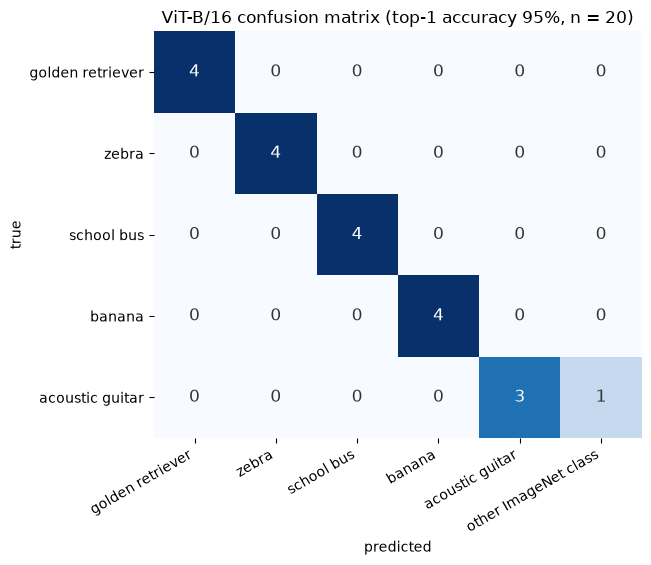

In [14]:
col_labels = [CATEGORY_TO_IMAGENET[c] for c in CATEGORIES] + ["other ImageNet class"]
idx_to_col = {CAT_TO_IDX[c]: j for j, c in enumerate(CATEGORIES)}
cm = np.zeros((len(CATEGORIES), len(col_labels)), dtype=int)
for cat, p in zip(sources.category, pred_idx.tolist()):
    cm[CATEGORIES.index(cat), idx_to_col.get(p, len(CATEGORIES))] += 1
pd.DataFrame(cm, index=col_labels[:-1], columns=col_labels).to_csv(OUT / "confusion_matrix.csv")


def plot_count_matrix(matrix, row_labels, col_labels, title, path, xlabel="predicted", ylabel="true"):
    """Heatmap of a small count matrix with the count written in every cell."""
    fig, ax = plt.subplots(figsize=(1.15 * len(col_labels) + 2.2, 0.75 * len(row_labels) + 2.0))
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max())
    for (r, c), v in np.ndenumerate(matrix):
        ax.text(c, r, str(v), ha="center", va="center", fontsize=12,
                color="white" if v > matrix.max() / 2 else "#333333")
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=30, ha="right")
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    for s in ax.spines.values():
        s.set_visible(False)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


plot_count_matrix(cm, col_labels[:-1], col_labels,
                  f"ViT-B/16 confusion matrix (top-1 accuracy {top1_acc:.0%}, n = {len(summary)})",
                  OUT / "task2_confusion_matrix.png")

### 2.5 All images with their top-one prediction

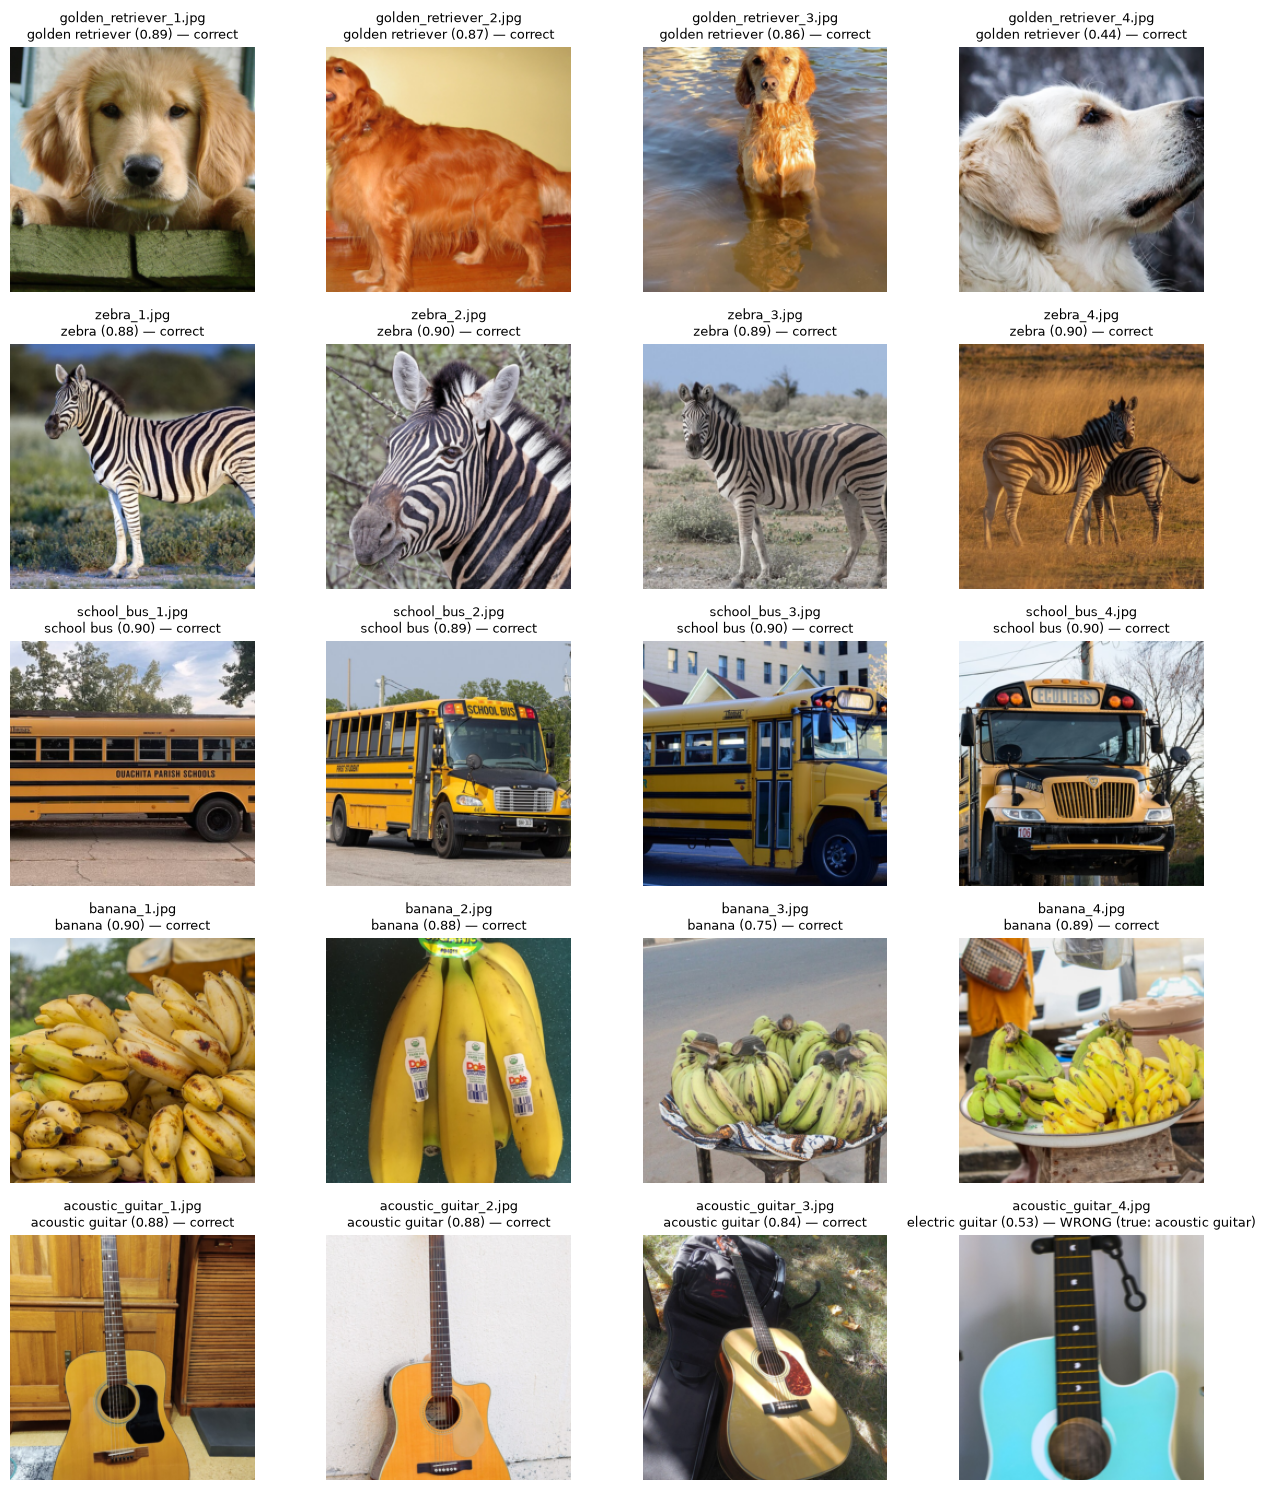

In [15]:
fig, axes = plt.subplots(5, 4, figsize=(13, 15))
for ax, (n, row) in zip(axes.flat, summary.iterrows()):
    ax.imshow(load_display_image(paths[n]).permute(1, 2, 0))
    mark = "correct" if row.top1_correct else f"WRONG (true: {CATEGORY_TO_IMAGENET[row.category]})"
    ax.set_title(f"{row.image}\n{row.top1_label} ({row.top1_prob:.2f}) — {mark}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUT / "task2_prediction_grid.png", dpi=130, bbox_inches="tight")
plt.show()

### 2.6 Images ranked by confidence in the true label

Least confident first.

In [16]:
summary.sort_values("true_label_prob").reset_index(drop=True)

,image,category,top1_label,top1_prob,true_label_prob,true_label_rank,top1_correct,top5_correct
0,acoustic_guitar_4.jpg,acoustic_guitar,electric guitar,0.5341,0.3730,2,False,True
1,golden_retriever_4.jpg,golden_retriever,golden retriever,0.4433,0.4433,1,True,True
2,banana_3.jpg,banana,banana,0.7499,0.7499,1,True,True
3,acoustic_guitar_3.jpg,acoustic_guitar,acoustic guitar,0.8393,0.8393,1,True,True
4,golden_retriever_3.jpg,golden_retriever,golden retriever,0.8597,0.8597,1,True,True
5,golden_retriever_2.jpg,golden_retriever,golden retriever,0.8657,0.8657,1,True,True
6,banana_2.jpg,banana,banana,0.8765,0.8765,1,True,True
7,acoustic_guitar_2.jpg,acoustic_guitar,acoustic guitar,0.8770,0.8770,1,True,True
8,acoustic_guitar_1.jpg,acoustic_guitar,acoustic guitar,0.8784,0.8784,1,True,True
9,zebra_1.jpg,zebra,zebra,0.8811,0.8811,1,True,True


In [17]:
# Top-five detail for the four least confident and two most confident images
order = summary.sort_values("true_label_prob").image.tolist()
focus = order[:4] + order[-2:]
with pd.option_context("display.max_rows", 200):
    display(top5[top5.image.isin(focus)].set_index(["image", "rank"]).loc[focus])

true_label     predicted_label  \
image                  rank                                         
acoustic_guitar_4.jpg  1      acoustic guitar     electric guitar   
                       2      acoustic guitar     acoustic guitar   
                       3      acoustic guitar               banjo   
                       4      acoustic guitar                pick   
                       5      acoustic guitar               cello   
golden_retriever_4.jpg 1     golden retriever    golden retriever   
                       2     golden retriever              kuvasz   
                       3     golden retriever  Labrador retriever   
                       4     golden retriever      Great Pyrenees   
                       5     golden retriever     Tibetan mastiff   
banana_3.jpg           1               banana              banana   
                       2               banana              barrow   
                       3               banana       grocery store   
                       4               banana              orange   
                       5               banana             mailbox   
acoustic_guitar_3.jpg  1      acoustic guitar     acoustic guitar   
                       2      acoustic guitar     electric guitar   
                       3      acoustic guitar           harmonica   
                       4      acoustic guitar            backpack   
                       5      acoustic guitar         French horn   
zebra_2.jpg            1                zebra               zebra   
                       2                zebra          hartebeest   
                       3                zebra             ostrich   
                       4                zebra               hyena   
                       5                zebra             warthog   
school_bus_4.jpg       1           school bus          school bus   
                       2           school bus       garbage truck   
                       3           school bus       traffic light   
                       4           school bus            snowplow   
                       5           school bus       trailer truck   

                             probability  is_true_label  
image                  rank                              
acoustic_guitar_4.jpg  1          0.5341          False  
                       2          0.3730           True  
                       3          0.0044          False  
                       4          0.0011          False  
                       5          0.0007          False  
golden_retriever_4.jpg 1          0.4433           True  
                       2          0.2718          False  
                       3          0.0702          False  
                       4          0.0255          False  
                       5          0.0048          False  
banana_3.jpg           1          0.7499           True  
                       2          0.0893          False  
                       3          0.0017          False  
                       4          0.0017          False  
                       5          0.0012          False  
acoustic_guitar_3.jpg  1          0.8393           True  
                       2          0.0064          False  
                       3          0.0012          False  
                       4          0.0009          False  
                       5          0.0007          False  
zebra_2.jpg            1          0.8999           True  
                       2          0.0017          False  
                       3          0.0009          False  
                       4          0.0007          False  
                       5          0.0005          False  
school_bus_4.jpg       1          0.9033           True  
                       2          0.0014          False  
                       3          0.0005          False  
                       4          0.0004          False  
                       5    

### 2.7 Discussion

19 of 20 correct (95%) and 20 of 20 in the top five; the only miss is `acoustic_guitar_4`, called an electric guitar. See the report for the full discussion.

### 2.8 How the fixed list of categories limits what I can ask

The model can only answer with one of its 1000 fixed labels, so anything outside that list can't be asked.